# P44 – Speed Dating: Is It a Match?
**Name:** DHIRAJ KUMAR  
**Roll No.:** H07  
**Enrollment No.:** 24004501210076  
**Division:** E  

**Problem:** Predict whether two people matched from their ratings of each other (attractive, sincere, intelligent, fun, ambitious, shared interests), age, field of study and interest correlation.  
**Dataset:** https://www.kaggle.com/datasets/annavictoria/speed-dating-experiment  
**Target (Y):** match (0/1)  
**Model:** Decision Tree  
**Main metric:** F1 and AUC


## Step 1: Load the libraries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, accuracy_score,
                             precision_score, recall_score, f1_score,
                             roc_auc_score)

import warnings
warnings.filterwarnings('ignore')

print("All libraries loaded successfully!")


All libraries loaded successfully!


## Step 2: Load the dataset


In [ ]:
df = pd.read_csv("Speed Dating Data.csv")
print("Shape (rows, columns):", df.shape)
print("\nFirst 5 rows:")
df.head()


Shape (rows, columns): (8378, 123)

First 5 rows:


,has_null,wave,gender,age,age_o,d_age,d_d_age,race,race_o,samerace,...,d_expected_num_interested_in_me,d_expected_num_matches,like,guess_prob_liked,d_like,d_guess_prob_liked,met,decision,decision_o,match
0,0,1,female,21.0,27.0,6,[4-6],'asian/pacific islander/asian-american',european/caucasian-american,0,...,[0-3],[3-5],7.0,6.0,[6-8],[5-6],0.0,1,0,0
1,0,1,female,21.0,22.0,1,[0-1],'asian/pacific islander/asian-american',european/caucasian-american,0,...,[0-3],[3-5],7.0,5.0,[6-8],[5-6],1.0,1,0,0
2,1,1,female,21.0,22.0,1,[0-1],'asian/pacific islander/asian-american','asian/pacific islander/asian-american',1,...,[0-3],[3-5],7.0,NaN,[6-8],[0-4],1.0,1,1,1
3,0,1,female,21.0,23.0,2,[2-3],'asian/pacific islander/asian-american',european/caucasian-american,0,...,[0-3],[3-5],7.0,6.0,[6-8],[5-6],0.0,1,1,1
4,0,1,female,21.0,24.0,3,[2-3],'asian/pacific islander/asian-american','latino/hispanic american',0,...,[0-3],[3-5],6.0,6.0,[6-8],[5-6],0.0,1,1,1


## Step 3: Understand the data


In [ ]:
print("=== Data Info ===")
print(df.info())
print("\n=== Missing values (top 15) ===")
print(df.isnull().sum().sort_values(ascending=False).head(15))
print("\n=== Duplicates ===")
print(df.duplicated().sum())
print("\n=== Target distribution ===")
print(df["match"].value_counts())


=== Data Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8378 entries, 0 to 8377
Columns: 123 entries, has_null to match
dtypes: float64(57), int64(7), object(59)
memory usage: 7.9+ MB
None

=== Missing values (top 15) ===
expected_num_interested_in_me    6578
expected_num_matches             1173
shared_interests_o               1076
shared_interests_partner         1067
ambitous_o                        722
ambition_partner                  712
met                               375
funny_o                           360
funny_partner                     350
guess_prob_liked                  309
intelligence_o                    306
intelligence_partner              296
sinsere_o                         287
sincere_partner                   277
like                              240
dtype: int64

=== Duplicates ===
0

=== Target distribution ===
match
0    6998
1    1380
Name: count, dtype: int64


✍️ **Write here:** Data dictionary table + 2 lines about what you noticed.

| Column | Meaning | Type | Keep/Drop |
|--------|---------|------|-----------|
| match | Mutual yes (target) | number | Keep (Y) |
| attractive / attractive_o | Attractiveness rating given / received | number | Keep |
| sincere / sinsere_o | Sincerity rating | number | Keep |
| intelligence / intelligence_o | Intelligence rating | number | Keep |
| funny / funny_o | Fun rating | number | Keep |
| ambition / ambitous_o | Ambition rating | number | Keep |
| shared_interests_partner / shared_interests_o | Shared interests | number | Keep |
| age / age_o | Age of person / partner | number | Keep |
| interests_correlate | Correlation of interests | number | Keep |
| field | Field of study | text | Keep |
| gender | Gender | text | Keep |
| samerace | Same race or not | number | Keep |
| decision / decision_o | Individual yes/no | number | DROP (leakage) |

**Noticed:** Many missing values in shared interests and ambition. Target is imbalanced (only ~16% matches). decision/decision_o must be dropped because match is built from them.


## Step 4: Prepare the target column (Y)


In [ ]:
print(df["match"].value_counts())
print("\nPercentage:")
print(df["match"].value_counts(normalize=True).round(3) * 100)


match
0    6998
1    1380
Name: count, dtype: int64

Percentage:
match
0    83.5
1    16.5
Name: proportion, dtype: float64


## Step 5: Clean the data


In [ ]:
useful_cols = [
    "attractive", "sincere", "intelligence", "funny", "ambition",
    "attractive_o", "sinsere_o", "intelligence_o", "funny_o", "ambitous_o",
    "shared_interests_partner", "shared_interests_o",
    "age", "age_o", "interests_correlate",
    "field", "gender", "samerace",
    "match"
]

df_clean = df[useful_cols].copy()
print("Selected columns:", df_clean.shape)

before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print("Duplicates removed:", before - len(df_clean))

for col in df_clean.columns:
    if pd.api.types.is_numeric_dtype(df_clean[col]):
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())
    else:
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Missing values after cleaning:", df_clean.isnull().sum().sum())
print("Final shape:", df_clean.shape)
df_clean.head()


Selected columns: (8378, 19)
Duplicates removed: 1
Missing values after cleaning: 0
Final shape: (8377, 19)


,attractive,sincere,intelligence,funny,ambition,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_partner,shared_interests_o,age,age_o,interests_correlate,field,gender,samerace,match
0,6.0,8.0,8.0,8.0,7.0,6.0,8.0,8.0,8.0,8.0,5.0,6.0,21.0,27.0,0.14,law,female,0,0
1,6.0,8.0,8.0,8.0,7.0,7.0,8.0,10.0,7.0,7.0,6.0,5.0,21.0,22.0,0.54,law,female,0,0
2,6.0,8.0,8.0,8.0,7.0,10.0,10.0,10.0,10.0,10.0,7.0,10.0,21.0,22.0,0.16,law,female,1,1
3,6.0,8.0,8.0,8.0,7.0,7.0,8.0,9.0,8.0,9.0,8.0,8.0,21.0,23.0,0.61,law,female,0,1
4,6.0,8.0,8.0,8.0,7.0,8.0,7.0,9.0,6.0,9.0,6.0,7.0,21.0,24.0,0.21,law,female,0,1


## Step 6: Explore the data with charts (EDA)


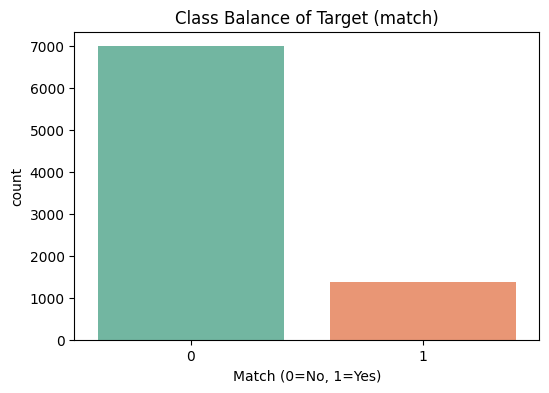

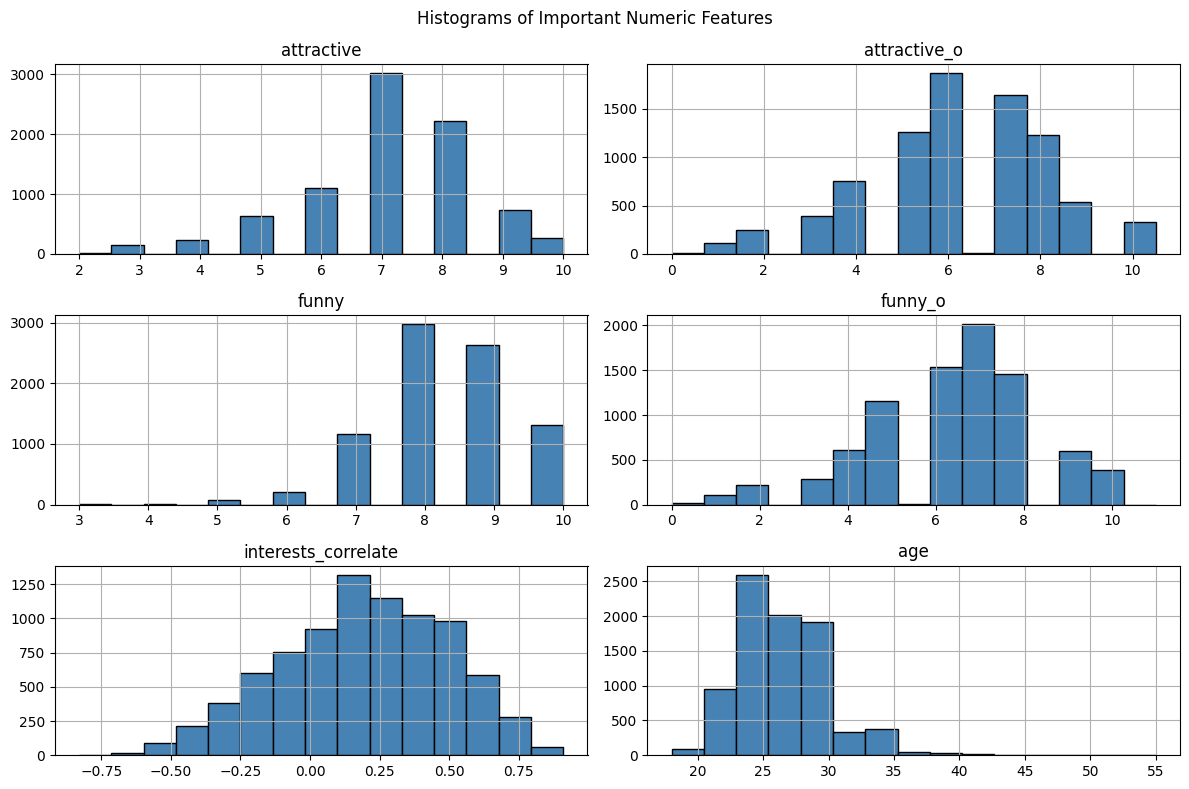

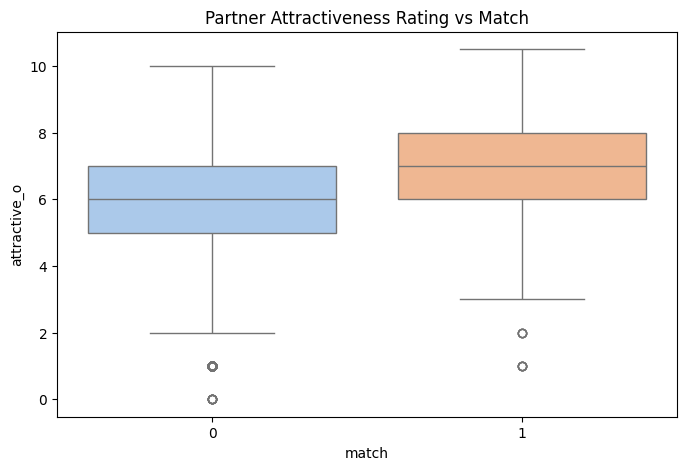

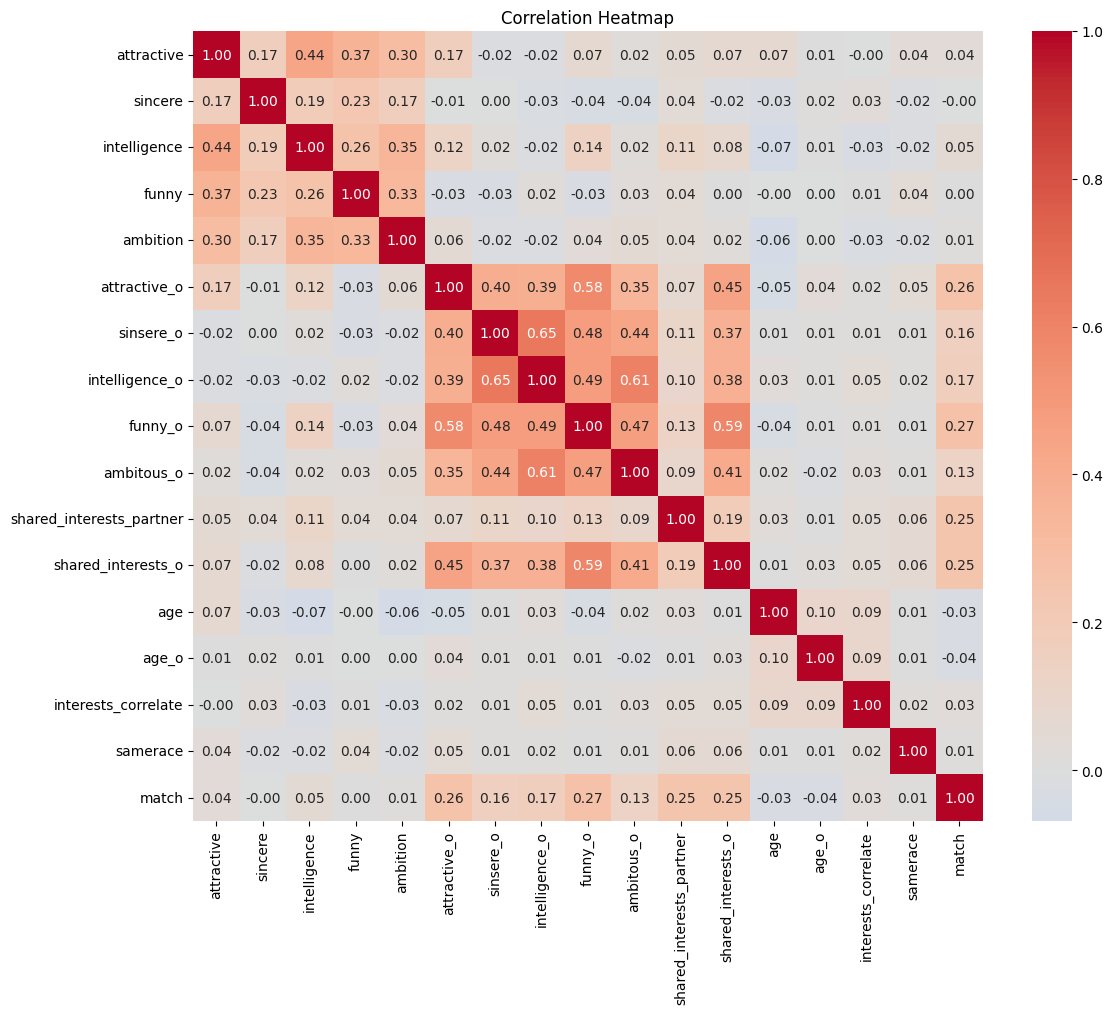

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x="match", data=df_clean, palette="Set2")
plt.title("Class Balance of Target (match)")
plt.xlabel("Match (0=No, 1=Yes)")
plt.show()

num_cols = ["attractive", "attractive_o", "funny", "funny_o", "interests_correlate", "age"]
df_clean[num_cols].hist(bins=15, figsize=(12,8), color="steelblue", edgecolor="black")
plt.suptitle("Histograms of Important Numeric Features")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
sns.boxplot(x="match", y="attractive_o", data=df_clean, palette="pastel")
plt.title("Partner Attractiveness Rating vs Match")
plt.show()

plt.figure(figsize=(12,10))
corr = df_clean.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


## Step 7: Create a new feature, encode and select features


In [ ]:
df_clean["chemistry"] = (df_clean["attractive"] + df_clean["attractive_o"] +
                         df_clean["funny"] + df_clean["funny_o"]) / 4

print("New feature chemistry created")
print(df_clean[["attractive", "attractive_o", "funny", "funny_o", "chemistry"]].head())

X = df_clean.drop("match", axis=1)
y = df_clean["match"]

le_y = LabelEncoder()
y = le_y.fit_transform(y)

X = pd.get_dummies(X, columns=["field", "gender"], drop_first=True)
print("After one-hot encoding shape:", X.shape)

selector = SelectKBest(score_func=f_classif, k=15)
X_selected = selector.fit_transform(X, y)
selected_features = X.columns[selector.get_support()].tolist()
print("Selected 15 best features:")
print(selected_features)

X = pd.DataFrame(X_selected, columns=selected_features)
print("Final X shape:", X.shape)


New feature chemistry created
   attractive  attractive_o  funny  funny_o  chemistry
0         6.0           6.0    8.0      8.0       7.00
1         6.0           7.0    8.0      7.0       7.00
2         6.0          10.0    8.0     10.0       8.50
3         6.0           7.0    8.0      8.0       7.25
4         6.0           8.0    8.0      6.0       7.00
After one-hot encoding shape: (8377, 236)
Selected 15 best features:
['intelligence', 'attractive_o', 'sinsere_o', 'intelligence_o', 'funny_o', 'ambitous_o', 'shared_interests_partner', 'shared_interests_o', 'chemistry', "field_'art history/medicine'", "field_'gs postbacc premed'", "field_'master in public administration'", "field_'masters in public administration'", 'field_money', 'field_religion']
Final X shape: (8377, 15)


## Step 8: Split into train and test


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train size:", X_train.shape)
print("Test size :", X_test.shape)
print("Train match rate:", round(y_train.mean(), 3))
print("Test match rate :", round(y_test.mean(), 3))
print("(Decision Tree does not need scaling)")


Train size: (6701, 15)
Test size : (1676, 15)
Train match rate: 0.165
Test match rate : 0.165
(Decision Tree does not need scaling)


## Step 9: Train baseline Decision Tree


Baseline Results:
  Model : Baseline (default)
  Accuracy : 0.7685
  Precision : 0.3133
  Recall : 0.3406
  F1 : 0.3264
  Specificity : 0.8529
  AUC : 0.5991

Classification Report:
              precision    recall  f1-score   support

    No Match       0.87      0.85      0.86      1400
       Match       0.31      0.34      0.33       276

    accuracy                           0.77      1676
   macro avg       0.59      0.60      0.59      1676
weighted avg       0.78      0.77      0.77      1676



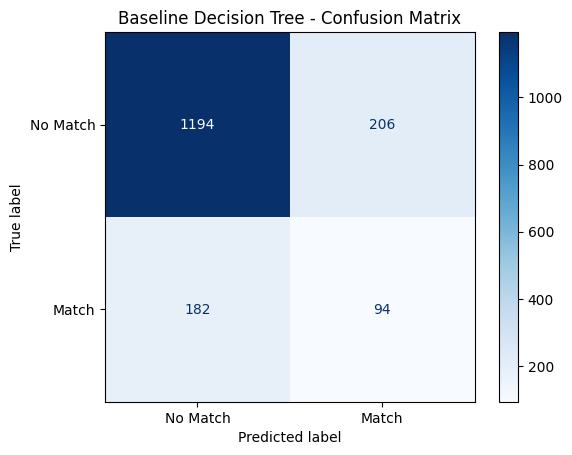

In [ ]:
results = []

def evaluate(name, model):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)
    f1   = f1_score(y_test, y_pred, zero_division=0)
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    auc  = roc_auc_score(y_test, y_prob)

    res = {
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1": round(f1, 4),
        "Specificity": round(spec, 4),
        "AUC": round(auc, 4)
    }
    results.append(res)
    return res, cm, y_pred

baseline = DecisionTreeClassifier(random_state=42)
res, cm, y_pred = evaluate("Baseline (default)", baseline)

print("Baseline Results:")
for k, v in res.items():
    print(" ", k, ":", v)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["No Match", "Match"]))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Match", "Match"])
disp.plot(cmap="Blues")
plt.title("Baseline Decision Tree - Confusion Matrix")
plt.show()


## Step 10: Try different settings (tuning)


criterion=gini, depth=5 : F1= 0.3912 , AUC= 0.7808
criterion=entropy, depth=5 : F1= 0.3923 , AUC= 0.7814


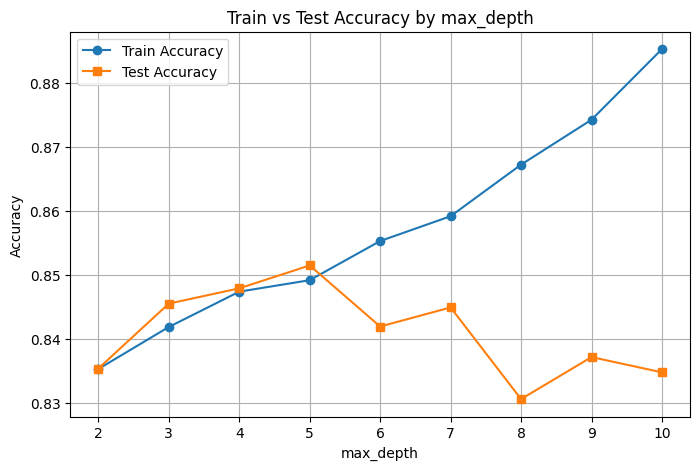

Choose depth where test accuracy is high and gap with train is small (usually 4 to 6).


In [ ]:
for crit in ["gini", "entropy"]:
    model = DecisionTreeClassifier(criterion=crit, random_state=42, max_depth=5)
    res, _, _ = evaluate("criterion=" + crit + ", depth=5", model)
    print(res["Model"], ": F1=", res["F1"], ", AUC=", res["AUC"])

train_acc = []
test_acc = []
depths = list(range(2, 11))

for d in depths:
    model = DecisionTreeClassifier(max_depth=d, random_state=42)
    model.fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, model.predict(X_train)))
    test_acc.append(accuracy_score(y_test, model.predict(X_test)))
    evaluate("max_depth=" + str(d), DecisionTreeClassifier(max_depth=d, random_state=42))

plt.figure(figsize=(8,5))
plt.plot(depths, train_acc, "o-", label="Train Accuracy")
plt.plot(depths, test_acc, "s-", label="Test Accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Train vs Test Accuracy by max_depth")
plt.legend()
plt.grid(True)
plt.show()

print("Choose depth where test accuracy is high and gap with train is small (usually 4 to 6).")


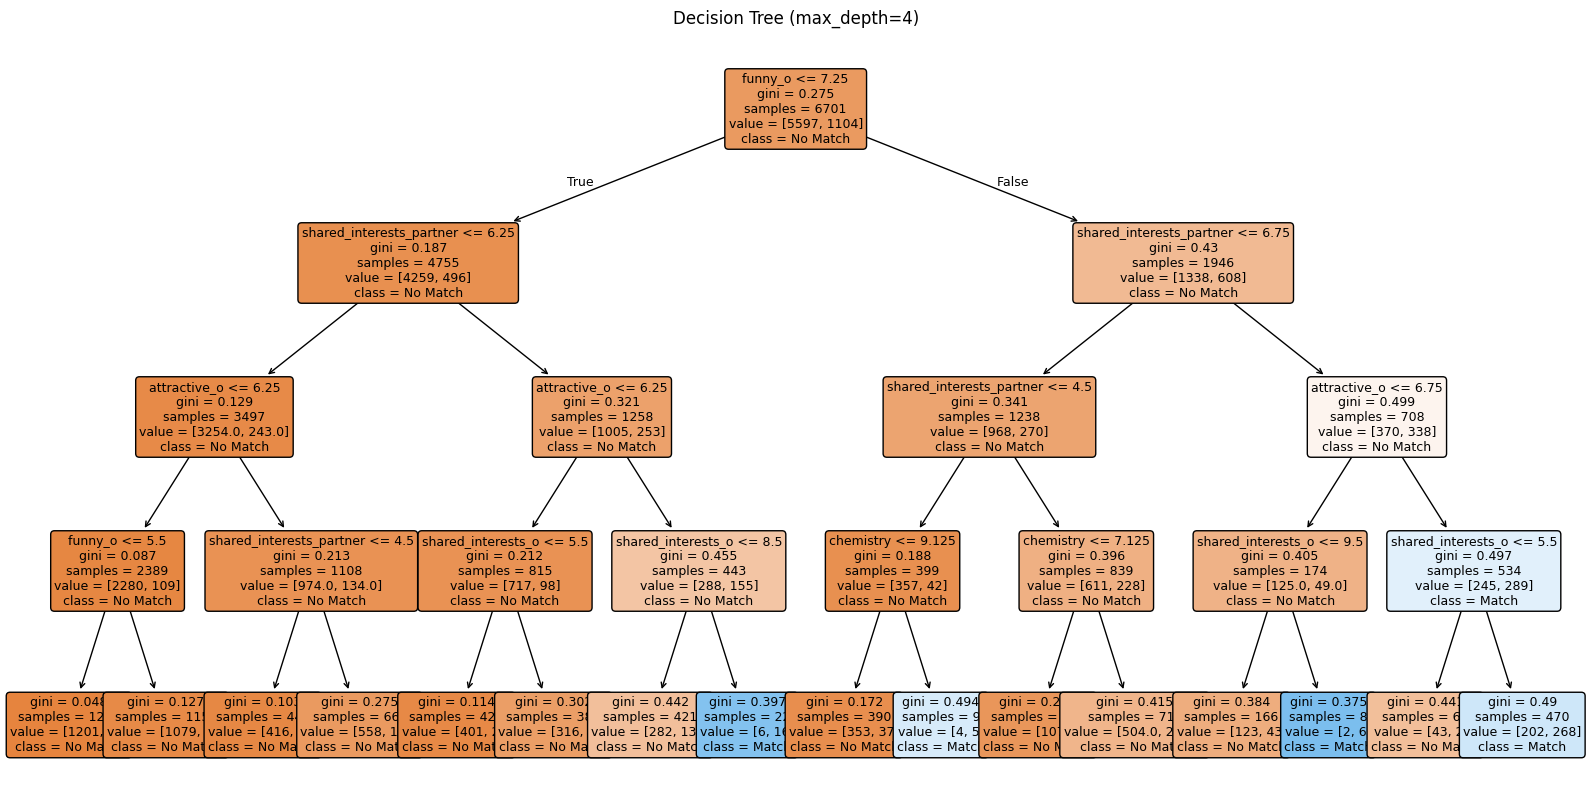

Root node feature: funny_o


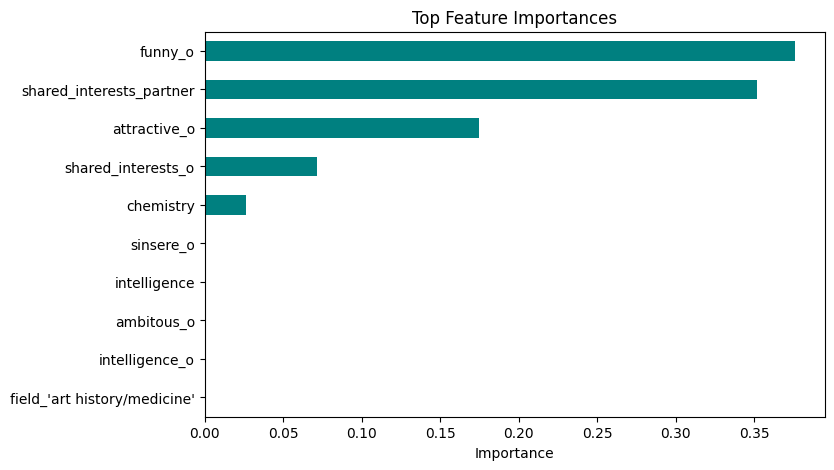

Top 3 features:
funny_o                     0.376019
shared_interests_partner    0.351754
attractive_o                0.174387
dtype: float64


In [ ]:
final_tree = DecisionTreeClassifier(max_depth=4, criterion="gini", random_state=42)
final_tree.fit(X_train, y_train)

plt.figure(figsize=(20,10))
plot_tree(final_tree, feature_names=selected_features, class_names=["No Match", "Match"],
          filled=True, rounded=True, fontsize=9, max_depth=4)
plt.title("Decision Tree (max_depth=4)")
plt.show()

print("Root node feature:", selected_features[final_tree.tree_.feature[0]])

imp = pd.Series(final_tree.feature_importances_, index=selected_features).sort_values(ascending=False)
plt.figure(figsize=(8,5))
imp.head(10).plot(kind="barh", color="teal")
plt.title("Top Feature Importances")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.show()

print("Top 3 features:")
print(imp.head(3))


## Step 11: Compare all settings and pick final model


=== Comparison Table (sorted by F1) ===
                     Model  Accuracy  Precision  Recall     F1  Specificity    AUC
criterion=entropy, depth=5    0.8502     0.5912  0.2935 0.3923       0.9600 0.7814
   criterion=gini, depth=5    0.8514     0.6015  0.2899 0.3912       0.9621 0.7808
               max_depth=5    0.8514     0.6015  0.2899 0.3912       0.9621 0.7808
               max_depth=4    0.8479     0.5766  0.2862 0.3826       0.9586 0.7795
               max_depth=3    0.8455     0.5603  0.2862 0.3789       0.9557 0.7629
               max_depth=7    0.8449     0.5580  0.2790 0.3720       0.9564 0.7588
              max_depth=10    0.8347     0.4968  0.2790 0.3573       0.9443 0.7345
               max_depth=6    0.8419     0.5414  0.2609 0.3521       0.9564 0.7693
               max_depth=9    0.8371     0.5108  0.2572 0.3422       0.9514 0.7300
        Baseline (default)    0.7685     0.3133  0.3406 0.3264       0.8529 0.5991
               max_depth=8    0.8305     0.4683

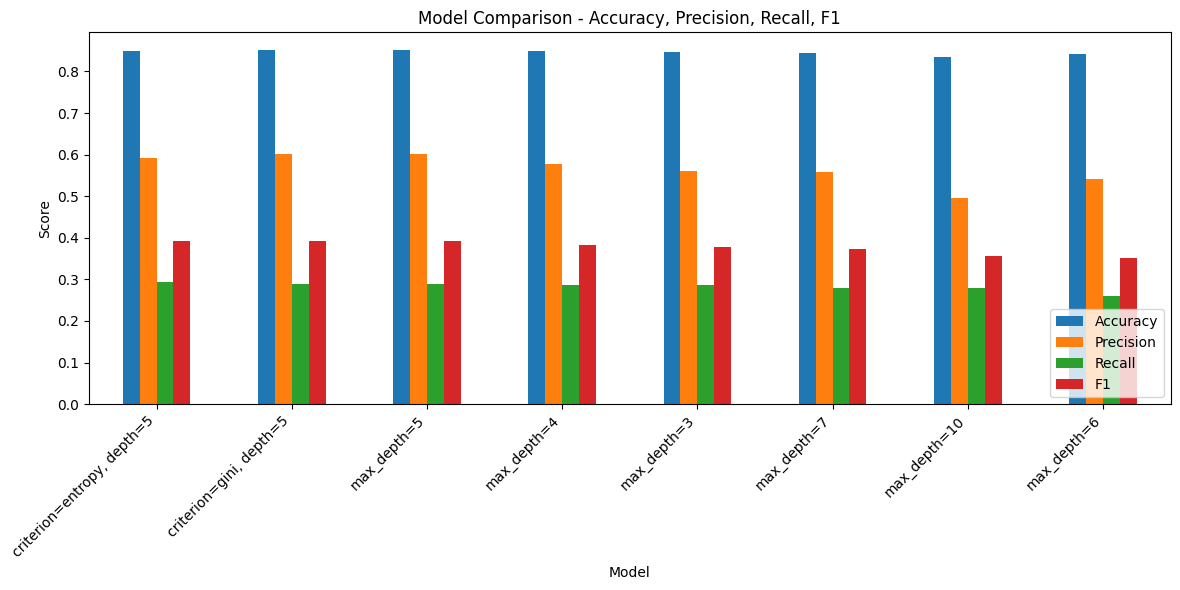

Best setting by F1: criterion=entropy, depth=5

Final Model Metrics:
  Model : FINAL (depth=5, gini)
  Accuracy : 0.8514
  Precision : 0.6015
  Recall : 0.2899
  F1 : 0.3912
  Specificity : 0.9621
  AUC : 0.7808


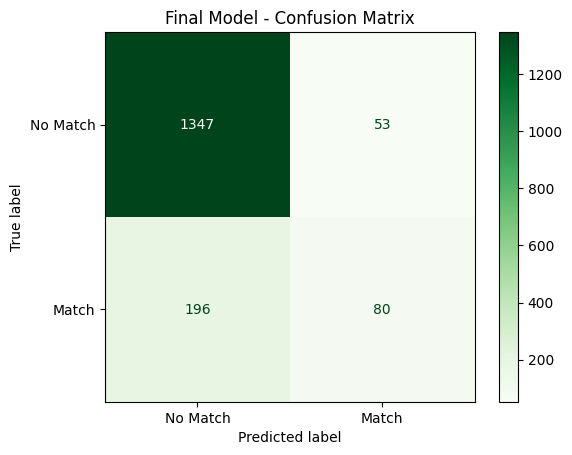

In [ ]:
results_df = pd.DataFrame(results)
results_df = results_df.drop_duplicates(subset=["Model"]).sort_values("F1", ascending=False)
print("=== Comparison Table (sorted by F1) ===")
print(results_df.to_string(index=False))

metrics = ["Accuracy", "Precision", "Recall", "F1"]
plot_df = results_df.set_index("Model")[metrics].head(8)
plot_df.plot(kind="bar", figsize=(12,6))
plt.title("Model Comparison - Accuracy, Precision, Recall, F1")
plt.ylabel("Score")
plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Best setting by F1:", results_df.iloc[0]["Model"])

final_model = DecisionTreeClassifier(max_depth=5, criterion="gini", random_state=42)
res_final, cm_final, y_pred_final = evaluate("FINAL (depth=5, gini)", final_model)

print("\nFinal Model Metrics:")
for k, v in res_final.items():
    print(" ", k, ":", v)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_final, display_labels=["No Match", "Match"])
disp.plot(cmap="Greens")
plt.title("Final Model - Confusion Matrix")
plt.show()


## Step 12: Predict 3 new inputs


In [ ]:
sample = X_test.iloc[:3].copy()

# Example 1: High chemistry (should predict Match)
sample.iloc[0] = 0
for col in sample.columns:
    if "attractive" in col or "funny" in col or "chemistry" in col or "shared" in col:
        sample.iloc[0, sample.columns.get_loc(col)] = 8.5
    elif "age" in col:
        sample.iloc[0, sample.columns.get_loc(col)] = 25
    else:
        sample.iloc[0, sample.columns.get_loc(col)] = 6

# Example 2: Low ratings (should predict No Match)
sample.iloc[1] = 0
for col in sample.columns:
    if "attractive" in col or "funny" in col or "chemistry" in col:
        sample.iloc[1, sample.columns.get_loc(col)] = 3
    elif "age" in col:
        sample.iloc[1, sample.columns.get_loc(col)] = 30
    else:
        sample.iloc[1, sample.columns.get_loc(col)] = 4

# Example 3: Average ratings
sample.iloc[2] = 0
for col in sample.columns:
    if "attractive" in col or "funny" in col or "chemistry" in col:
        sample.iloc[2, sample.columns.get_loc(col)] = 6.5
    elif "age" in col:
        sample.iloc[2, sample.columns.get_loc(col)] = 27
    else:
        sample.iloc[2, sample.columns.get_loc(col)] = 5.5

preds = final_model.predict(sample)
probs = final_model.predict_proba(sample)[:, 1]
labels = le_y.inverse_transform(preds)

print("=== 3 New Predictions ===")
for i in range(3):
    print("\nInput", i+1, ":")
    pred_label = "Match" if labels[i] == 1 else "No Match"
    print("  Prediction :", labels[i], "(" + pred_label + ")")
    print("  Probability of Match:", round(probs[i], 3))
    if i == 0:
        sense = "Yes - high ratings"
    elif i == 1:
        sense = "Yes - low ratings"
    else:
        sense = "Borderline / average case"
    print("  Makes sense?", sense)


=== 3 New Predictions ===

Input 1 :
  Prediction : 1 (Match)
  Probability of Match: 0.617
  Makes sense? Yes - high ratings

Input 2 :
  Prediction : 0 (No Match)
  Probability of Match: 0.024
  Makes sense? Yes - low ratings

Input 3 :
  Prediction : 0 (No Match)
  Probability of Match: 0.105
  Makes sense? Borderline / average case


## Step 13: Conclusion


In [ ]:
print("Notebook ran successfully from top to bottom.")
print("Final model is ready.")


Notebook ran successfully from top to bottom.
Final model is ready.
